In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker


plt.rcParams.update({
    'font.family':'serif',
    'font.serif':'Times New Roman',
    'font.size': 16,        # Default text size
    'axes.titlesize': 18,   # Title size
    'axes.labelsize': 18,   # X and Y axis label size
    'xtick.labelsize': 16,  # X tick label size
    'ytick.labelsize': 16,  # Y tick label size
    'legend.fontsize': 16,  # Legend font size
    'figure.titlesize': 20  # Figure-level title size
})

In [7]:
B1 = pd.read_csv('../data/groundwater/Temp/BA0000007FD53E41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B2 = pd.read_csv('../data/groundwater/Temp/AE000000824F6A41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B3 = pd.read_csv('../data/groundwater/Temp/23000000824F2141_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
A = pd.read_csv('../data/groundwater/Temp/9600000082456D41_092926005501_1.csv', skiprows=24, on_bad_lines='skip', sep=';')

start = pd.Timestamp('2026-09-28 19:55:01')
end = pd.Timestamp('2026-10-01 09:00:01')

B1_time = pd.to_datetime(B1['Date'] + ' ' + B1['Time'])
B2_time = pd.to_datetime(B2['Date'] + ' ' + B2['Time'])
B3_time = pd.to_datetime(B3['Date'] + ' ' + B3['Time'])
A_time = pd.to_datetime(A['Date'] + ' ' + A['Time'])

B1 = B1.loc[(B1_time >= start) & (B1_time <= end)]
B2 = B2.loc[(B2_time >= start) & (B2_time <= end)]
B3 = B3.loc[(B3_time >= start) & (B3_time <= end)]
A = A.loc[(A_time >= start) & (A_time <= end)]


In [8]:
tides = pd.read_csv('../data/water_levels/QUINTA_tides_2030.csv')
tides['dates'] = pd.to_datetime(tides['dates'], utc=True)

tides['dates'] = tides['dates'].dt.tz_localize(None)
tides_window = tides[(tides['dates'] >= start) & (tides['dates'] <= end)]

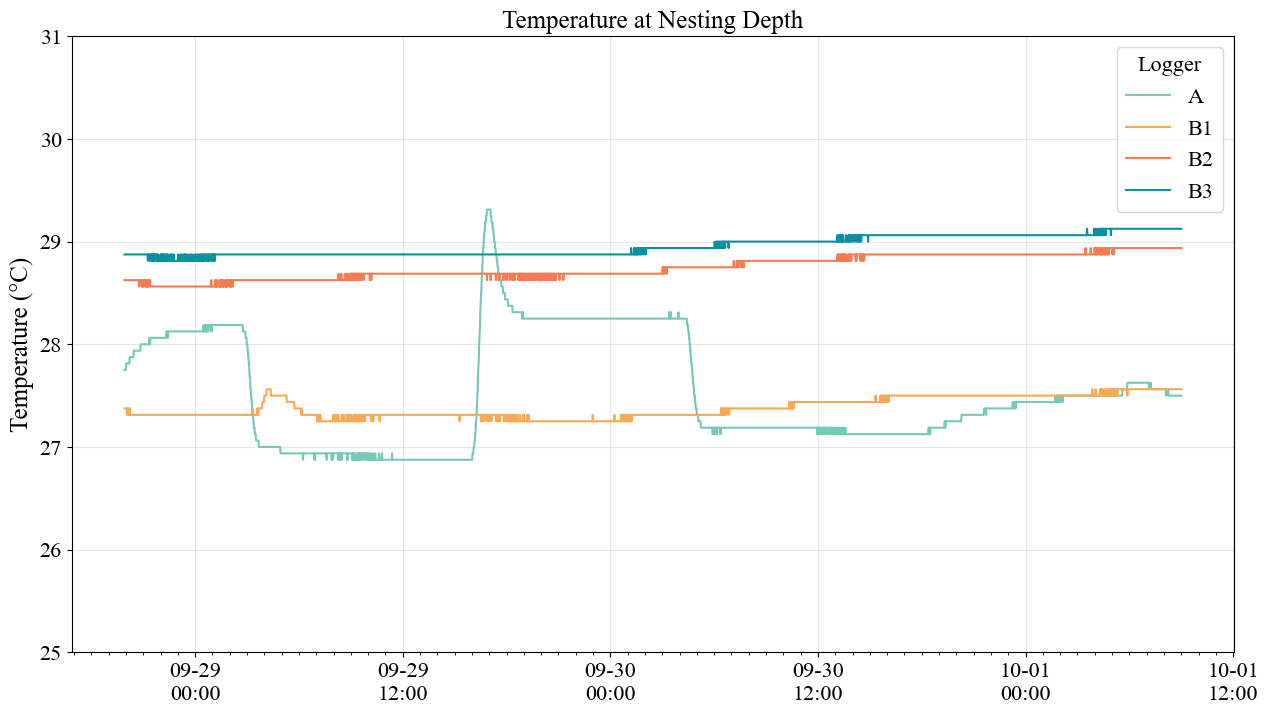

In [9]:
colors = {"A": "#74c9b9", "B1": "#f8a953", "B2": "#f47c53", "B3": "#0a91a1"}

fig, ax1 = plt.subplots(1, 1, figsize=(15, 8))

for name, data in {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}.items():
    datetime = pd.to_datetime(data['Date'] + ' ' + data['Time'])
    temperature = pd.to_numeric(data['Value'], errors='coerce')
    ax1.plot(datetime, temperature, linewidth=1.5, label=name, color=colors[name])

ax1.set_title('Temperature at Nesting Depth')
ax1.set_ylabel('Temperature (°C)')
ax1.set_ylim(ymin=25, ymax=31)
ax1.legend(title='Logger')
ax1.grid(alpha=0.3)

ax1.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax1.xaxis.set_major_locator(mdates.AutoDateLocator())
ax1.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
